# Assignment 4 - COMP 551:
## Learning with Sequence Data (RNNs and Transformers)

**Group 2:**

Maeve Côté

Barry Zhang

Nicholas Belev

## Dataset and Preparations

In [ ]:
import re
import time
import math
import random
from collections import Counter

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# imports for visuals: training curves and confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [ ]:
# For reproducibility, we induce determinism across all random elements
RANDOM_SEED = 2026

rng = np.random.default_rng(RANDOM_SEED)
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
torch.cuda.manual_seed_all(RANDOM_SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

def seed_worker(worker_id):
    worker_seed = RANDOM_SEED + worker_id
    np.random.seed(worker_seed)
    random.seed(worker_seed)

g = torch.Generator()
g.manual_seed(RANDOM_SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [ ]:
# Loading the dataset
dataset = load_dataset("ag_news")
train_full = dataset["train"]   # 120,000 examples
test_data = dataset["test"]     # 7,600 examples

print(train_full)
print(test_data)
print(train_full[0])

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/18.6M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/1.23M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'label'],
    num_rows: 120000
})
Dataset({
    features: ['text', 'label'],
    num_rows: 7600
})
{'text': "Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\\band of ultra-cynics, are seeing green again.", 'label': 2}


Note the data entries each contain: Title, Description, Class Index where:

Class Index: Class IDs 1-4 where 1-World, 2-Sports, 3-Business, 4-Sci/Tech

In [ ]:
label_names = ["World", "Sports", "Business", "Sci/Tech"]
num_classes = 4

## Task 1: Implemeting the LSTM Classifier from Scratch

In [ ]:
# Train and validation split: 90/10.
indices = np.arange(len(train_full))
train_idx, val_idx = train_test_split(
    indices,
    test_size=0.10,
    random_state=RANDOM_SEED,
    shuffle=True,
    stratify=train_full["label"]
)

train_data = train_full.select(train_idx)
val_data = train_full.select(val_idx)

print("Train size:", len(train_data))
print("Val size:", len(val_data))
print("Test size:", len(test_data))

Train size: 108000
Val size: 12000
Test size: 7600


In [ ]:
# Tokenization + regex helper to break down titles / descriptions
def tokenize(text):
    text = text.lower()
    # keep words and simple apostrophe forms
    return re.findall(r"\b\w+(?:'\w+)?\b", text)

sample = "Apple's shares jumped 5% after the announcement."
print(tokenize(sample))

["apple's", 'shares', 'jumped', '5', 'after', 'the', 'announcement']


In [ ]:
# Vocabulary including constraints and special symbols needed for LSTM tokenization
PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"

PAD_IDX = 0
UNK_IDX = 1

MIN_FREQ = 3   # frequency higher than 2 means frequency higher or equal (>=) to 3.

counter = Counter()
for example in train_data:
    tokens = tokenize(example["text"])
    counter.update(tokens)

vocab_tokens = [tok for tok, freq in counter.items() if freq >= MIN_FREQ]
vocab = {PAD_TOKEN: PAD_IDX, UNK_TOKEN: UNK_IDX}

for tok in vocab_tokens:
    if tok not in vocab:
        vocab[tok] = len(vocab)

id_to_token = {idx: tok for tok, idx in vocab.items()}

print("Vocab size:", len(vocab))
print(counter.most_common(20))

Vocab size: 35181
[('the', 185014), ('to', 108537), ('a', 101976), ('of', 88824), ('in', 86806), ('and', 62763), ('on', 51846), ('for', 45634), ('39', 40080), ('s', 36122), ('that', 25158), ('with', 24103), ('as', 22825), ('at', 22516), ('its', 19979), ('is', 19860), ('new', 19210), ('by', 18839), ('said', 18219), ('it', 17797)]


In [ ]:
# Numericalization of text
MAX_LEN = 128

def numericalize(text, vocab, max_len=MAX_LEN):
    tokens = tokenize(text)
    ids = [vocab.get(tok, UNK_IDX) for tok in tokens]
    ids = ids[:max_len]
    length = len(ids)
    return ids, length

In [ ]:
# Implementing PyTorch dataset that returns: Token ID list, Sequence Length, Label, original text for error analysis
class AGNewsLSTMDataset(Dataset):
    def __init__(self, hf_dataset, vocab, max_len=128):
        self.data = hf_dataset
        self.vocab = vocab
        self.max_len = max_len

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        item = self.data[idx]
        text = item["text"]
        label = item["label"]
        input_ids, length = numericalize(text, self.vocab, self.max_len)
        return {
            "input_ids": input_ids,
            "length": length,
            "label": label,
            "text": text
        }

train_ds = AGNewsLSTMDataset(train_data, vocab, MAX_LEN)
val_ds = AGNewsLSTMDataset(val_data, vocab, MAX_LEN)
test_ds = AGNewsLSTMDataset(test_data, vocab, MAX_LEN)

In [ ]:
# Collate function with padding, using mask-aware pooling
def collate_fn(batch):
    batch_input_ids = [item["input_ids"] for item in batch]
    batch_lengths = torch.tensor([item["length"] for item in batch], dtype=torch.long)
    batch_labels = torch.tensor([item["label"] for item in batch], dtype=torch.long)
    batch_texts = [item["text"] for item in batch]

    max_batch_len = max(len(ids) for ids in batch_input_ids)

    padded = []
    for ids in batch_input_ids:
        pad_len = max_batch_len - len(ids)
        padded_ids = ids + [PAD_IDX] * pad_len
        padded.append(padded_ids)

    input_ids = torch.tensor(padded, dtype=torch.long)

    # mask: 1 for real tokens, 0 for pad
    attention_mask = (input_ids != PAD_IDX).long()

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "lengths": batch_lengths,
        "labels": batch_labels,
        "texts": batch_texts
    }

In [ ]:
BATCH_SIZE = 64

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    worker_init_fn=seed_worker,
    generator=g
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    worker_init_fn=seed_worker,
    generator=g
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    worker_init_fn=seed_worker,
    generator=g
)

# Ensuring batch properties align with expected shape
batch = next(iter(train_loader))
for k, v in batch.items():
    if isinstance(v, torch.Tensor):
        print(k, v.shape)
    else:
        print(k, type(v), len(v))

input_ids torch.Size([64, 75])
attention_mask torch.Size([64, 75])
lengths torch.Size([64])
labels torch.Size([64])
texts <class 'list'> 64


In [ ]:
# LSTM Model
class LSTMClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        emb_dim=100,
        hidden_dim=128,
        num_layers=1,
        dropout=0.2,
        num_classes=4,
        bidirectional=False, # We will experiment with enabling bidirectionality to gauge performance changes
        pad_idx=0,
        pooling="mean"   # "mean" or "last"
    ):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_idx)
        self.bidirectional = bidirectional
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        self.pooling = pooling

        lstm_dropout = dropout if num_layers > 1 else 0.0

        self.lstm = nn.LSTM(
            input_size=emb_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=lstm_dropout,
            bidirectional=bidirectional
        )

        output_dim = hidden_dim * 2 if bidirectional else hidden_dim

        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(output_dim, num_classes)

    # For this project we stay consistent with masked mean pooling rather than last token pooling
    def masked_mean_pool(self, lstm_out, attention_mask):
        # lstm_out: (B, T, H)
        # attention_mask: (B, T)
        mask = attention_mask.unsqueeze(-1).float()   # (B, T, 1)
        masked_output = lstm_out * mask
        summed = masked_output.sum(dim=1)            # (B, H)
        lengths = mask.sum(dim=1).clamp(min=1e-8)    # (B, 1)
        return summed / lengths

    # Unused in either model
    # def last_token_pool(self, lstm_out, lengths):
    #     # take hidden state at the last real token
    #     # lengths are original sequence lengths
    #     idx = (lengths - 1).clamp(min=0)
    #     idx = idx.view(-1, 1, 1).expand(-1, 1, lstm_out.size(2))
    #     last_hidden = lstm_out.gather(dim=1, index=idx).squeeze(1)
    #     return last_hidden

    def forward(self, input_ids, attention_mask, lengths):
        x = self.embedding(input_ids)         # (B, T, E)
        lstm_out, _ = self.lstm(x)            # (B, T, H)

        if self.pooling == "mean":
            pooled = self.masked_mean_pool(lstm_out, attention_mask)
        elif self.pooling == "last":
            pooled = self.last_token_pool(lstm_out, lengths)
        else:
            raise ValueError("pooling must be 'mean' or 'last'")

        pooled = self.dropout(pooled)
        logits = self.classifier(pooled)
        return logits

We use masked mean pooling to convert the sequence of LSTM hidden states into a single vector for classification. Since sequences are padded to a uniform length, we apply an attention mask to ignore PAD tokens and average only over valid tokens. This ensures the representation reflects the full input without being affected by padding. Compared to last-token pooling, which relies on a single position, masked mean pooling is more stable and better suited to bidirectional LSTMs, where information is distributed across the entire sequence.

In [ ]:
# Recommended baseline parameters as per the project instructions
VOCAB_SIZE = len(vocab)
EMB_DIM = 100
HIDDEN_DIM = 128
NUM_LAYERS = 1
DROPOUT = 0.2
LR = 1e-3
EPOCHS = 6
CLIP_NORM = 1.0

# Instantiation of the baseline LSTM
model = LSTMClassifier(
    vocab_size=VOCAB_SIZE,
    emb_dim=EMB_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT,
    num_classes=num_classes,
    bidirectional=False,
    pad_idx=PAD_IDX,
    pooling="mean"
).to(device)

criterion = nn.CrossEntropyLoss() # We use the cross entropy loss function for gradient descent
optimizer = torch.optim.Adam(model.parameters(), lr=LR) # Adam (Adaptive moment estimation) algorithm for gradient descent

num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {num_params:,}")

Trainable parameters: 3,636,376


In [ ]:
# Training / Evaluation helper function.  Performs training with attention masking and aggregates loss.
def run_epoch(model, dataloader, optimizer=None, train=True):
    if train:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    all_preds = []
    all_labels = []

    for batch in dataloader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        lengths = batch["lengths"].to(device)
        labels = batch["labels"].to(device)

        with torch.set_grad_enabled(train):
            logits = model(input_ids, attention_mask, lengths)
            loss = criterion(logits, labels)

            if train:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP_NORM)
                optimizer.step()

        total_loss += loss.item() * input_ids.size(0)
        preds = logits.argmax(dim=1)

        all_preds.extend(preds.cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

    avg_loss = total_loss / len(dataloader.dataset)
    acc = accuracy_score(all_labels, all_preds)
    return avg_loss, acc

In [ ]:
# Main training loop
history = {
    "train_loss": [],
    "val_loss": [],
    "val_acc": []
}

best_val_acc = 0.0
best_state = None

# Iterate through all epochs, tracking the models that produce the best accuracy and validation loss
for epoch in range(1, EPOCHS + 1):
    start = time.time()

    train_loss, train_acc = run_epoch(model, train_loader, optimizer=optimizer, train=True)
    val_loss, val_acc = run_epoch(model, val_loader, optimizer=None, train=False)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    elapsed = time.time() - start

    print(
        f"Epoch {epoch:02d} | "
        f"train_loss={train_loss:.4f} | "
        f"train_acc={train_acc:.4f} | "
        f"val_loss={val_loss:.4f} | "
        f"val_acc={val_acc:.4f} | "
        f"time={elapsed:.1f}s"
    )

Epoch 01 | train_loss=0.4809 | train_acc=0.8276 | val_loss=0.3230 | val_acc=0.8932 | time=22.0s
Epoch 02 | train_loss=0.2572 | train_acc=0.9136 | val_loss=0.2750 | val_acc=0.9087 | time=21.3s
Epoch 03 | train_loss=0.1915 | train_acc=0.9362 | val_loss=0.2691 | val_acc=0.9106 | time=20.4s
Epoch 04 | train_loss=0.1439 | train_acc=0.9511 | val_loss=0.3003 | val_acc=0.9082 | time=21.1s
Epoch 05 | train_loss=0.1066 | train_acc=0.9639 | val_loss=0.3088 | val_acc=0.9073 | time=29.0s
Epoch 06 | train_loss=0.0750 | train_acc=0.9748 | val_loss=0.3437 | val_acc=0.9061 | time=21.0s


In [ ]:
# The best model found by our training / validation
model.load_state_dict(best_state)
print("Best val acc:", best_val_acc)

Best val acc: 0.9105833333333333


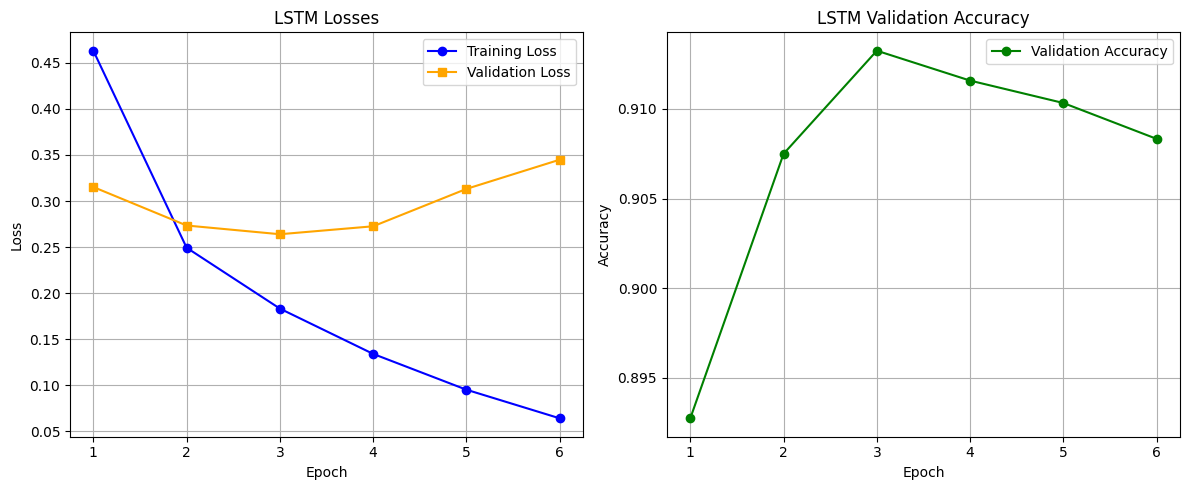

In [ ]:
epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(12, 5))

# Left Plot: Combined Loss
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history["train_loss"], marker='o', label='Training Loss', color='blue')
plt.plot(epochs_range, history["val_loss"], marker='s', label='Validation Loss', color='orange')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM Losses")
plt.legend()
plt.grid(True)

# Right Plot: Validation Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history["val_acc"], marker='o', label='Validation Accuracy', color='green')
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LSTM Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

These visuals tell us that validation loss was (relatively) minimized by the third epoch, which is also when validation accuracy reached its relative maximum.  Training loss, continued to decrease consistently, approaching near-zero.  This is consistent with overfitting and worsening generalization as the LSTM model over-learns features and word relationships.

In [ ]:
# Final Test Results on the held-out data
test_loss, test_acc = run_epoch(model, test_loader, optimizer=None, train=False)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")

Test loss: 0.2733
Test accuracy: 0.9083


In [ ]:
# Helper to gather LSTM predictions and labels, necessary input to the confusion matrix
def get_predictions(model, dataloader):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for batch in dataloader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            lengths = batch["lengths"].to(device)
            labels = batch["labels"].to(device)

            logits = model(input_ids, attention_mask, lengths)
            preds = logits.argmax(dim=1)

            all_preds.extend(preds.cpu().tolist())
            all_labels.extend(labels.cpu().tolist())

    return all_labels, all_preds

<Figure size 600x600 with 0 Axes>

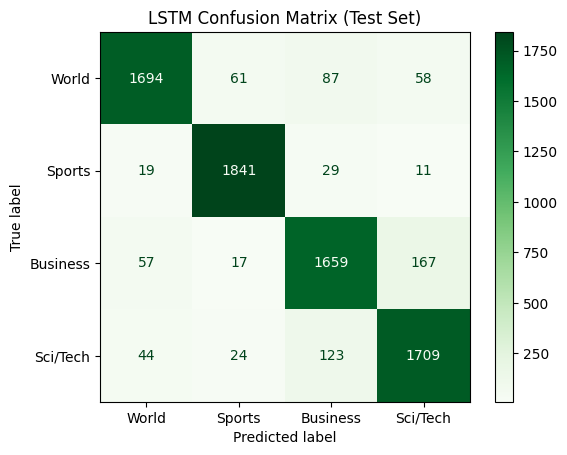

In [ ]:
# Plotting the confusion matrix to understand patterns in (mis-)classifications
y_true, y_pred = get_predictions(model, test_loader)

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_names)

plt.figure(figsize=(6, 6))
disp.plot(cmap="Greens", values_format="d")
plt.title("LSTM Confusion Matrix (Test Set)")
plt.show()

We can verify the accuracy `0.9104` intuitively by summing the diagonal of dark green squares in the confusion matrix. This is the total number of correctly classified articles by our LSTM model. We then divide this value by `7600` (the total article count in the test set).

In [ ]:
# Helper to gather misclassified examples and the full corresponding data entry
def collect_misclassifications(model, dataloader, max_examples=10):
    model.eval()
    mistakes = []

    with torch.no_grad():
        for batch in dataloader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            lengths = batch["lengths"].to(device)
            labels = batch["labels"].to(device)
            texts = batch["texts"]

            logits = model(input_ids, attention_mask, lengths)
            preds = logits.argmax(dim=1)

            for text, true_label, pred_label in zip(texts, labels.cpu().tolist(), preds.cpu().tolist()):
                if true_label != pred_label:
                    mistakes.append({
                        "text": text,
                        "true": label_names[true_label],
                        "pred": label_names[pred_label]
                    })
                    if len(mistakes) >= max_examples:
                        return mistakes
    return mistakes

In [ ]:
mistakes = collect_misclassifications(model, test_loader, max_examples=10)

for i, ex in enumerate(mistakes, 1):
    print(f"Example {i}")
    print("True:", ex["true"])
    print("Pred:", ex["pred"])
    print("Text:", ex["text"][:400])
    print("-" * 80)

Example 1
True: Sci/Tech
Pred: Business
Text: IBM to hire even more new workers By the end of the year, the computing giant plans to have its biggest headcount since 1991.
--------------------------------------------------------------------------------
Example 2
True: Sci/Tech
Pred: Business
Text: Rivals Try to Turn Tables on Charles Schwab By MICHAEL LIEDTKE     SAN FRANCISCO (AP) -- With its low prices and iconoclastic attitude, discount stock broker Charles Schwab Corp. (SCH) represented an annoying stone in Wall Street's wing-tipped shoes for decades...
--------------------------------------------------------------------------------
Example 3
True: World
Pred: Business
Text: Venezuela Prepares for Chavez Recall Vote Supporters and rivals warn of possible fraud; government says Chavez's defeat could produce turmoil in world oil market.
--------------------------------------------------------------------------------
Example 4
True: Sci/Tech
Pred: Business
Text: Promoting a Shared Vis

In [ ]:
# Reproducible utilities for extra LSTM experiments
from torch.nn.utils.rnn import pack_padded_sequence
from sklearn.metrics import accuracy_score
import pandas as pd
import time

def reset_all_seeds(seed=RANDOM_SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def make_lstm_dataloaders(batch_size=BATCH_SIZE):
    local_g = torch.Generator()
    local_g.manual_seed(RANDOM_SEED)

    train_loader_local = DataLoader(
        train_ds,
        batch_size=batch_size,
        shuffle=True,
        collate_fn=collate_fn,
        worker_init_fn=seed_worker,
        generator=local_g,
    )
    val_loader_local = DataLoader(
        val_ds,
        batch_size=batch_size,
        shuffle=False,
        collate_fn=collate_fn,
        worker_init_fn=seed_worker,
        generator=local_g,
    )
    test_loader_local = DataLoader(
        test_ds,
        batch_size=batch_size,
        shuffle=False,
        collate_fn=collate_fn,
        worker_init_fn=seed_worker,
        generator=local_g,
    )
    return train_loader_local, val_loader_local, test_loader_local

class PackedLastLSTMClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        emb_dim=100,
        hidden_dim=128,
        num_layers=1,
        dropout=0.2,
        num_classes=4,
        bidirectional=False,
        pad_idx=0,
    ):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_idx)
        self.bidirectional = bidirectional

        lstm_dropout = dropout if num_layers > 1 else 0.0
        self.lstm = nn.LSTM(
            input_size=emb_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=lstm_dropout,
            bidirectional=bidirectional,
        )

        output_dim = hidden_dim * 2 if bidirectional else hidden_dim
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(output_dim, num_classes)

    def forward(self, input_ids, attention_mask, lengths):
        x = self.embedding(input_ids)
        packed = pack_padded_sequence(
            x, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, (h_n, _) = self.lstm(packed)

        if self.bidirectional:
            pooled = torch.cat((h_n[-2], h_n[-1]), dim=1)
        else:
            pooled = h_n[-1]

        pooled = self.dropout(pooled)
        logits = self.classifier(pooled)
        return logits

def run_epoch_lstm_variant(model, dataloader, criterion, optimizer=None, train=True, clip_norm=1.0):
    if train:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    all_preds = []
    all_labels = []

    for batch in dataloader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        lengths = batch["lengths"].to(device)
        labels = batch["labels"].to(device)

        with torch.set_grad_enabled(train):
            logits = model(input_ids, attention_mask, lengths)
            loss = criterion(logits, labels)

            if train:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), clip_norm)
                optimizer.step()

        total_loss += loss.item() * input_ids.size(0)
        preds = logits.argmax(dim=1)
        all_preds.extend(preds.cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

    avg_loss = total_loss / len(dataloader.dataset)
    acc = accuracy_score(all_labels, all_preds)
    return avg_loss, acc

def train_lstm_variant(
    model_factory,
    model_name,
    epochs=EPOCHS,
    lr=LR,
    clip_norm=CLIP_NORM,
    batch_size=BATCH_SIZE,
):
    reset_all_seeds(RANDOM_SEED)
    train_loader_local, val_loader_local, test_loader_local = make_lstm_dataloaders(
        batch_size=batch_size
    )

    model = model_factory().to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {"train_loss": [], "val_loss": [], "val_acc": [], "epoch_time": []}
    best_val_acc = -1.0
    best_state = None

    for epoch in range(1, epochs + 1):
        start = time.time()

        train_loss, train_acc = run_epoch_lstm_variant(
            model,
            train_loader_local,
            criterion,
            optimizer=optimizer,
            train=True,
            clip_norm=clip_norm,
        )
        val_loss, val_acc = run_epoch_lstm_variant(
            model,
            val_loader_local,
            criterion,
            optimizer=None,
            train=False,
            clip_norm=clip_norm,
        )
        elapsed = time.time() - start

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["epoch_time"].append(elapsed)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        print(
            f"[{model_name}] Epoch {epoch:02d} | "
            f"train_loss={train_loss:.4f} | train_acc={train_acc:.4f} | "
            f"val_loss={val_loss:.4f} | val_acc={val_acc:.4f} | time={elapsed:.1f}s"
        )

    model.load_state_dict(best_state)

    test_loss, test_acc = run_epoch_lstm_variant(
        model,
        test_loader_local,
        criterion,
        optimizer=None,
        train=False,
        clip_norm=clip_norm,
    )

    return {
        "name": model_name,
        "model": model,
        "history": history,
        "best_val_acc": best_val_acc,
        "test_loss": test_loss,
        "test_acc": test_acc,
        "num_params": sum(p.numel() for p in model.parameters() if p.requires_grad),
        "avg_epoch_time_s": float(np.mean(history["epoch_time"])),
        "mistakes": collect_misclassifications(model, test_loader_local, max_examples=10),
        "test_loader": test_loader_local,
    }

def summarise_split_lengths(hf_dataset, split_name, max_len=MAX_LEN):
    raw_lengths = [len(tokenize(example["text"])) for example in hf_dataset]
    return {
        "Split": split_name,
        "Mean raw length": round(float(np.mean(raw_lengths)), 1),
        "Median raw length": int(np.median(raw_lengths)),
        "95th pct": int(np.percentile(raw_lengths, 95)),
        "% truncated @ max_len": round(100.0 * np.mean(np.array(raw_lengths) > max_len), 2),
    }

def evaluate_lstm_by_raw_length(model, dataloader):
    bucket_names = ["1-32", "33-64", "65-96", "97+"]
    bucket_total = {name: 0 for name in bucket_names}
    bucket_correct = {name: 0 for name in bucket_names}

    def bucketize(length):
        if length <= 32:
            return "1-32"
        if length <= 64:
            return "33-64"
        if length <= 96:
            return "65-96"
        return "97+"

    model.eval()
    with torch.no_grad():
        for batch in dataloader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            lengths = batch["lengths"].to(device)
            labels = batch["labels"].to(device)

            logits = model(input_ids, attention_mask, lengths)
            preds = logits.argmax(dim=1).cpu().tolist()
            gold = labels.cpu().tolist()

            for text, y_true, y_pred in zip(batch["texts"], gold, preds):
                raw_len = len(tokenize(text))
                bucket = bucketize(raw_len)
                bucket_total[bucket] += 1
                bucket_correct[bucket] += int(y_true == y_pred)

    rows = []
    for bucket in bucket_names:
        total = bucket_total[bucket]
        rows.append(
            {
                "Raw token length bucket": bucket,
                "Examples": total,
                "Accuracy": round(bucket_correct[bucket] / total, 4) if total > 0 else np.nan,
            }
        )
    return pd.DataFrame(rows)

In [ ]:
# Extra experiment: compare LSTM variants under the same setup
EXTRA_LSTM_EPOCHS = EPOCHS  # change to 4 if runtime is tight

lstm_variant_results = {}

lstm_variant_results["UniLSTM + masked mean"] = train_lstm_variant(
    lambda: LSTMClassifier(
        vocab_size=VOCAB_SIZE,
        emb_dim=EMB_DIM,
        hidden_dim=HIDDEN_DIM,
        num_layers=NUM_LAYERS,
        dropout=DROPOUT,
        num_classes=num_classes,
        bidirectional=False,
        pad_idx=PAD_IDX,
        pooling="mean",
    ),
    model_name="UniLSTM + masked mean",
    epochs=EXTRA_LSTM_EPOCHS,
)

lstm_variant_results["BiLSTM + masked mean"] = train_lstm_variant(
    lambda: LSTMClassifier(
        vocab_size=VOCAB_SIZE,
        emb_dim=EMB_DIM,
        hidden_dim=HIDDEN_DIM,
        num_layers=NUM_LAYERS,
        dropout=DROPOUT,
        num_classes=num_classes,
        bidirectional=True,
        pad_idx=PAD_IDX,
        pooling="mean",
    ),
    model_name="BiLSTM + masked mean",
    epochs=EXTRA_LSTM_EPOCHS,
)

lstm_variant_results["UniLSTM + packed last state"] = train_lstm_variant(
    lambda: PackedLastLSTMClassifier(
        vocab_size=VOCAB_SIZE,
        emb_dim=EMB_DIM,
        hidden_dim=HIDDEN_DIM,
        num_layers=NUM_LAYERS,
        dropout=DROPOUT,
        num_classes=num_classes,
        bidirectional=False,
        pad_idx=PAD_IDX,
    ),
    model_name="UniLSTM + packed last state",
    epochs=EXTRA_LSTM_EPOCHS,
)

lstm_variant_table = pd.DataFrame(
    [
        {
            "Model": result["name"],
            "Best Val Accuracy": round(100 * result["best_val_acc"], 2),
            "Test Accuracy": round(100 * result["test_acc"], 2),
            "Trainable Parameters": result["num_params"],
            "Avg Epoch Time (s)": round(result["avg_epoch_time_s"], 1),
        }
        for result in lstm_variant_results.values()
    ]
).sort_values("Test Accuracy", ascending=False).reset_index(drop=True)

display(lstm_variant_table)

best_lstm_name = lstm_variant_table.loc[0, "Model"]
print(f"Best LSTM variant by test accuracy: {best_lstm_name}")

[UniLSTM + masked mean] Epoch 01 | train_loss=0.4791 | train_acc=0.8263 | val_loss=0.3212 | val_acc=0.8931 | time=21.9s
[UniLSTM + masked mean] Epoch 02 | train_loss=0.2579 | train_acc=0.9135 | val_loss=0.2784 | val_acc=0.9073 | time=21.4s
[UniLSTM + masked mean] Epoch 03 | train_loss=0.1920 | train_acc=0.9356 | val_loss=0.2688 | val_acc=0.9105 | time=21.0s
[UniLSTM + masked mean] Epoch 04 | train_loss=0.1439 | train_acc=0.9517 | val_loss=0.2775 | val_acc=0.9107 | time=31.6s
[UniLSTM + masked mean] Epoch 05 | train_loss=0.1063 | train_acc=0.9642 | val_loss=0.3130 | val_acc=0.9080 | time=20.6s
[UniLSTM + masked mean] Epoch 06 | train_loss=0.0758 | train_acc=0.9741 | val_loss=0.3554 | val_acc=0.9047 | time=26.9s
[BiLSTM + masked mean] Epoch 01 | train_loss=0.4583 | train_acc=0.8334 | val_loss=0.3190 | val_acc=0.8929 | time=23.0s
[BiLSTM + masked mean] Epoch 02 | train_loss=0.2493 | train_acc=0.9168 | val_loss=0.2690 | val_acc=0.9106 | time=22.6s
[BiLSTM + masked mean] Epoch 03 | train_lo

,Model,Best Val Accuracy,Test Accuracy,Trainable Parameters,Avg Epoch Time (s)
0,UniLSTM + packed last state,91.48,91.09,3636376,27.3
1,BiLSTM + masked mean,91.18,91.07,3754648,23.0
2,UniLSTM + masked mean,91.07,90.82,3636376,23.9


Best LSTM variant by test accuracy: UniLSTM + packed last state


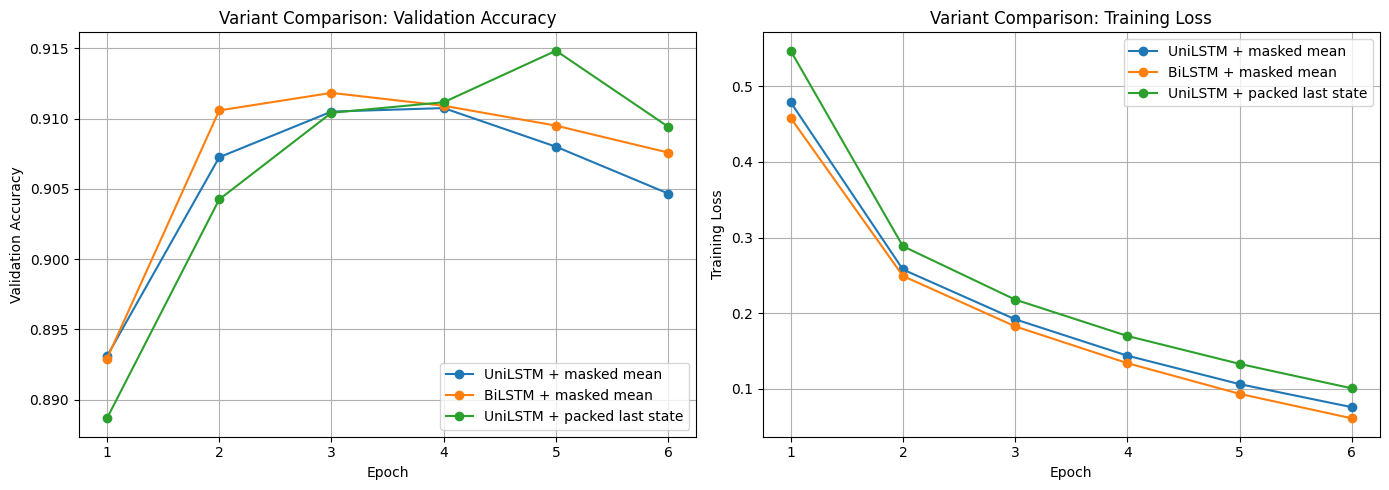

,Split,Mean raw length,Median raw length,95th pct,% truncated @ max_len
0,Train,39.4,39,58,0.09
1,Validation,39.5,39,58,0.09
2,Test,39.2,38,57,0.09


Length-bucket accuracy for UniLSTM + packed last state:


,Raw token length bucket,Examples,Accuracy
0,1-32,1885,0.8796
1,33-64,5517,0.9231
2,65-96,171,0.8713
3,97+,27,0.8519


Sample mistakes from the packed-last-state model:
Example 1
True: Sci/Tech
Pred: Business
Text: Card fraud unit nets 36,000 cards In its first two years, the UK's dedicated card fraud unit, has recovered 36,000 stolen cards and 171 arrests - and estimates it saved 65m.
--------------------------------------------------------------------------------
Example 2
True: Sci/Tech
Pred: Business
Text: IBM to hire even more new workers By the end of the year, the computing giant plans to have its biggest headcount since 1991.
--------------------------------------------------------------------------------
Example 3
True: Sci/Tech
Pred: Business
Text: Rivals Try to Turn Tables on Charles Schwab By MICHAEL LIEDTKE     SAN FRANCISCO (AP) -- With its low prices and iconoclastic attitude, discount stock broker Charles Schwab Corp. (SCH) represented an annoying stone in Wall Street's wing-tipped shoes for decades...
--------------------------------------------------------------------------------
Exam

In [ ]:
import matplotlib.pyplot as plt

# Curves for the three LSTM variants
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
for name, result in lstm_variant_results.items():
    epochs = range(1, len(result["history"]["val_acc"]) + 1)
    plt.plot(epochs, result["history"]["val_acc"], marker="o", label=name)
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Variant Comparison: Validation Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
for name, result in lstm_variant_results.items():
    epochs = range(1, len(result["history"]["train_loss"]) + 1)
    plt.plot(epochs, result["history"]["train_loss"], marker="o", label=name)
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Variant Comparison: Training Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Length / truncation analysis for the best LSTM variant
split_length_df = pd.DataFrame(
    [
        summarise_split_lengths(train_data, "Train"),
        summarise_split_lengths(val_data, "Validation"),
        summarise_split_lengths(test_data, "Test"),
    ]
)
display(split_length_df)

best_lstm_model = lstm_variant_results[best_lstm_name]["model"]
best_lstm_test_loader = lstm_variant_results[best_lstm_name]["test_loader"]
length_bucket_df = evaluate_lstm_by_raw_length(best_lstm_model, best_lstm_test_loader)

print(f"Length-bucket accuracy for {best_lstm_name}:")
display(length_bucket_df)

print("Sample mistakes from the packed-last-state model:")
for i, ex in enumerate(lstm_variant_results["UniLSTM + packed last state"]["mistakes"][:5], 1):
    print(f"Example {i}")
    print("True:", ex["true"])
    print("Pred:", ex["pred"])
    print("Text:", ex["text"][:300])
    print("-" * 80)


Interestingly, a frequest mistake in this sampling is `Prediction: Business` for `Ground Truth: Sci/Tech`.  This accounts for 6 out of the 10 featured examples.

### Task 1 **Beyond the Minimum**: Bidirectional LSTM

This experiment tests whether allowing bidirectionality improves classification performance.  The intuition is that if the tokens and hidden layers are able to reference eachother and determine co-dependence both forwards (the normal way we read a sentence) and backwards, this extra conditional information may result in a more accurate LSTM model.

In [ ]:
# Recommended baseline parameters
VOCAB_SIZE = len(vocab)
EMB_DIM = 100
HIDDEN_DIM = 128
NUM_LAYERS = 1
DROPOUT = 0.2
LR = 1e-3
EPOCHS = 6
CLIP_NORM = 1.0

# Instantiation
model = LSTMClassifier(
    vocab_size=VOCAB_SIZE,
    emb_dim=EMB_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT,
    num_classes=num_classes,
    bidirectional=True,
    pad_idx=PAD_IDX,
    pooling="mean" # To be consistent with baseline model above
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {num_params:,}")

Trainable parameters: 3,754,648


In [ ]:
# Main training loop
history = {
    "train_loss": [],
    "val_loss": [],
    "val_acc": []
}

best_val_acc = 0.0
best_state = None

for epoch in range(1, EPOCHS + 1):
    start = time.time()

    train_loss, train_acc = run_epoch(model, train_loader, optimizer=optimizer, train=True)
    val_loss, val_acc = run_epoch(model, val_loader, optimizer=None, train=False)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    elapsed = time.time() - start

    print(
        f"Epoch {epoch:02d} | "
        f"train_loss={train_loss:.4f} | "
        f"train_acc={train_acc:.4f} | "
        f"val_loss={val_loss:.4f} | "
        f"val_acc={val_acc:.4f} | "
        f"time={elapsed:.1f}s"
    )

Epoch 01 | train_loss=0.4631 | train_acc=0.8312 | val_loss=0.3152 | val_acc=0.8928 | time=23.1s
Epoch 02 | train_loss=0.2493 | train_acc=0.9160 | val_loss=0.2735 | val_acc=0.9075 | time=22.9s
Epoch 03 | train_loss=0.1833 | train_acc=0.9381 | val_loss=0.2640 | val_acc=0.9133 | time=44.5s
Epoch 04 | train_loss=0.1342 | train_acc=0.9544 | val_loss=0.2726 | val_acc=0.9116 | time=23.4s
Epoch 05 | train_loss=0.0953 | train_acc=0.9675 | val_loss=0.3132 | val_acc=0.9103 | time=23.0s
Epoch 06 | train_loss=0.0643 | train_acc=0.9780 | val_loss=0.3449 | val_acc=0.9083 | time=30.4s


In [ ]:
# The best model found by our training / validation
model.load_state_dict(best_state)
print("Best val acc:", best_val_acc)

Best val acc: 0.91325


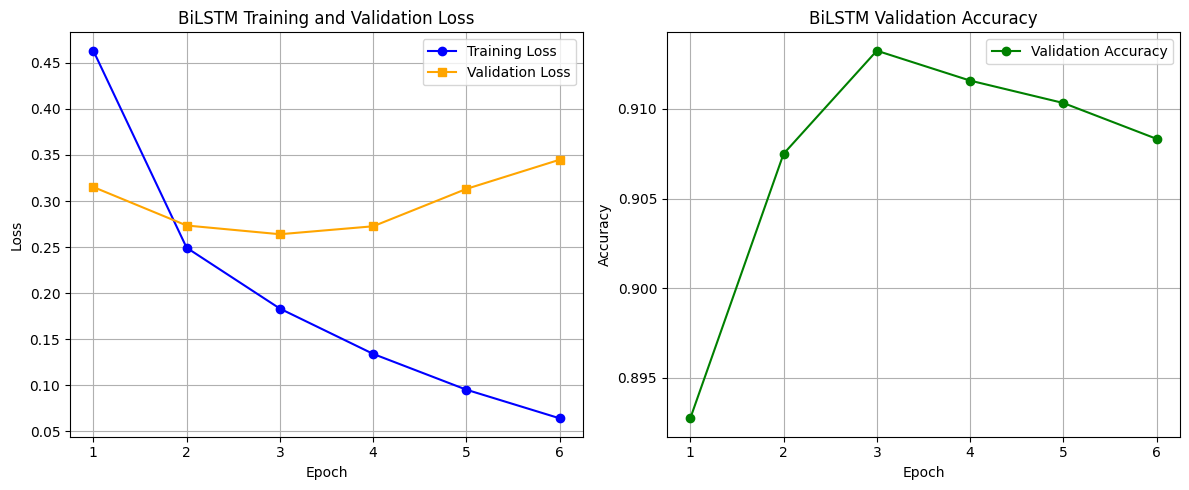

In [ ]:
# Training Figures and key Visuals
epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(12, 5))

# Combined Training and Validation Loss
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history["train_loss"], marker='o', label='Training Loss', color='blue')
plt.plot(epochs_range, history["val_loss"], marker='s', label='Validation Loss', color='orange')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("BiLSTM Training and Validation Loss")
plt.legend()
plt.grid(True)

# Validation Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history["val_acc"], marker='o', label='Validation Accuracy', color='green')
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("BiLSTM Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# Final Test Results on the held-out data
test_loss, test_acc = run_epoch(model, test_loader, optimizer=None, train=False)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")

Test loss: 0.2773
Test accuracy: 0.9097


<Figure size 600x600 with 0 Axes>

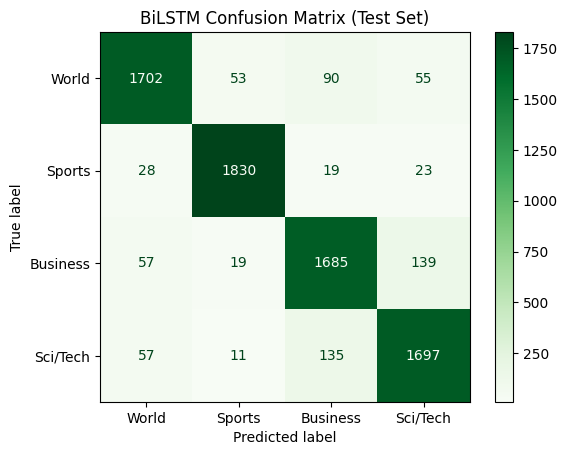

In [ ]:
# Plotting the confusion matrix to understand patterns in (mis-)classifications
y_true, y_pred = get_predictions(model, test_loader)

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_names)

plt.figure(figsize=(6, 6))
disp.plot(cmap="Greens", values_format="d")
plt.title("BiLSTM Confusion Matrix (Test Set)")
plt.show()

In [ ]:
mistakes = collect_misclassifications(model, test_loader, max_examples=10)

for i, ex in enumerate(mistakes, 1):
    print(f"Example {i}")
    print("True:", ex["true"])
    print("Pred:", ex["pred"])
    print("Text:", ex["text"][:400])
    print("-" * 80)

Example 1
True: Sci/Tech
Pred: Business
Text: Card fraud unit nets 36,000 cards In its first two years, the UK's dedicated card fraud unit, has recovered 36,000 stolen cards and 171 arrests - and estimates it saved 65m.
--------------------------------------------------------------------------------
Example 2
True: Sci/Tech
Pred: Business
Text: Super ant colony hits Australia A giant 100km colony of ants  which has been discovered in Melbourne, Australia, could threaten local insect species.
--------------------------------------------------------------------------------
Example 3
True: Sci/Tech
Pred: Business
Text: Rivals Try to Turn Tables on Charles Schwab By MICHAEL LIEDTKE     SAN FRANCISCO (AP) -- With its low prices and iconoclastic attitude, discount stock broker Charles Schwab Corp. (SCH) represented an annoying stone in Wall Street's wing-tipped shoes for decades...
--------------------------------------------------------------------------------
Example 4
True: World
Pred: Bu

The 10 sampled mistakes from the Bidirectional model show a similar pattern of errors to the forward-only LSTM.  Namely, `Sci/Tech` appears to be a major source of confusion, often mistaken with `Business` and `World`.  

One could argue that the training data is partly to blame.  The labelling of the dataset could be "open to interpretation": take article that mentions Charles Schwab, Wall Street, an low prices which could reasonably be considered `Business` though its ground-truth label is `Sci/Tech`.

Ultimately, the test accuracy of the BiLSTM is nearly identical to that of the one-way LSTM.  This may be due to the BiLSTM's higher complexity without a corresponding increase in useful signal. The dataset contains overlapping and ambiguously labeled categories (especially between `Sci/Tech`, `Business`, and `World`), so access to future context does not meaningfully reduce uncertainty. Instead, the additional parameters in the bidirectional model may make it slightly more sensitive to noise and harder to optimize under the same training conditions, resulting in no gain—and a small drop—in test accuracy compared to the simpler one-way LSTM.

## Task 2: Fine-Tune a Pretrained Transformer

In [ ]:
# Tokenization for BERT-like models
from transformers import AutoTokenizer

# Constant
MAX_LENGTH = 128

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

# To apply to multiple samples
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH
    )

sample = "Apple's shares jumped 5% after the announcement."
unbelievable_sample = "This is unbelievably interesting!"
encoding = tokenizer(sample,
                     padding="max_length",
                     truncation=True,
                     max_length=MAX_LENGTH,
                     return_tensors="pt")

unbelievable_encoding = tokenizer(unbelievable_sample,
                     padding="max_length",
                     truncation=True,
                     max_length=MAX_LENGTH,
                     return_tensors="pt")

token_ids = encoding['input_ids'].squeeze().tolist()
subwords = tokenizer.convert_ids_to_tokens(token_ids)

unbelievable_token_ids = unbelievable_encoding['input_ids'].squeeze().tolist()
unbelievable_subwords = tokenizer.convert_ids_to_tokens(unbelievable_token_ids)

# Remove the '[PAD]' tokens
clean_subwords = [word for word in subwords if word not in {'[PAD]'}]
unbelievable_clean_subwords = [word for word in unbelievable_subwords if word not in {'[PAD]'}]

print("Comparaison of the LSTM tokenization and the BERT tokenization:")
print("LSTM: " + str(tokenize(sample)))
print("BERT: " + str(clean_subwords))

print("\nUnbelievable example: " + str(unbelievable_clean_subwords))


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Comparaison of the LSTM tokenization and the BERT tokenization:
LSTM: ["apple's", 'shares', 'jumped', '5', 'after', 'the', 'announcement']
BERT: ['[CLS]', 'apple', "'", 's', 'shares', 'jumped', '5', '%', 'after', 'the', 'announcement', '.', '[SEP]']

Unbelievable example: ['[CLS]', 'this', 'is', 'un', '##bel', '##ie', '##va', '##bly', 'interesting', '!', '[SEP]']


#### **Word-Level vs. Subword Tokenization**
We can see that the LSTM 'word-level' tokenizer loses some information by removing punctuation (like the '%' symbol). Furthermore, it doesn't break words like "apple's" into multiple parts. Treating every variation of a word as a unique token will add a significant number of tokens to the vocabulary, leading to inefficiencies and out-of-vocabulary ([UNK]) errors.

The BERT model's 'subword' approach solves this by splitting rare or complex words into smaller, meaningful pieces.

E.g., "apple's" is broken down into "apple", " ' ", and "s".

It also breaks down words like "unbelievably" into meaningful subwords (like prefixes and suffixes) so it can construct the meaning of the complete word from its pieces.

E.g., "unbelievably" becomes "un", "##believ", and "##ably". Note that the tokenizer puts '##' in front of the pieces to signify to the model that it is a continuation of a bigger word and should not be treated as a standalone word.

This allows the model to parse words it has never seen before and deduce their meaning using its past experience with those subwords, similar to how a human would process a new vocabulary word.

#### **Padding and the Attention Mask**
During training, PyTorch requires sequences to be grouped into batches, which means every input tensor in a batch must have a fixed, uniform length. To satisfy this hardware constraint, we either truncate longer sequences or pad shorter sequences with [PAD] tokens.

However, because Transformers process all tokens simultaneously using self-attention, the model would naturally try to process these meaningless [PAD] tokens. To prevent this, the tokenizer outputs an attention mask, a binary tensor that tells the model which tokens are actually part of the input (1) and which are padding (0). This effectively forces the model to ignore the padding, preventing it from interpreting information where there is none.

In [ ]:
# Loading the model
from transformers import AutoModelForSequenceClassification
model = AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=4)

# Calculate total parameters trainable parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total Parameters: {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,}")

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Total Parameters: 66,956,548
Trainable Parameters: 66,956,548


In [ ]:
# Validation split (90/10)
train_val_split = train_full.train_test_split(test_size=0.1, seed=2026)
train_data = train_val_split["train"]
val_data = train_val_split["test"]

print(f"Training set size: {len(train_data)}")
print(f"Validation set size: {len(val_data)}")

Training set size: 108000
Validation set size: 12000


In [ ]:
# Reuse the exact Task 1 split for the Transformer experiments
train_data = train_full.select(train_idx.tolist() if hasattr(train_idx, "tolist") else train_idx)
val_data = train_full.select(val_idx.tolist() if hasattr(val_idx, "tolist") else val_idx)

print("Reused Task 1 split for Transformer fine-tuning.")
print(f"Training set size: {len(train_data)}")
print(f"Validation set size: {len(val_data)}")

Reused Task 1 split for Transformer fine-tuning.
Training set size: 108000
Validation set size: 12000


In [ ]:
# Tokenizing the dataset
tokenized_train = train_data.map(tokenize_function, batched=True)
tokenized_val = val_data.map(tokenize_function, batched=True)
tokenized_test = test_data.map(tokenize_function, batched=True)

Map:   0%|          | 0/108000 [00:00<?, ? examples/s]

Map:   0%|          | 0/12000 [00:00<?, ? examples/s]

Map:   0%|          | 0/7600 [00:00<?, ? examples/s]

In [ ]:
!pip install evaluate
# Evalutaion metric
import evaluate

accuracy_metric = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return accuracy_metric.compute(predictions=predictions, references=labels)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 7.7 MB/s eta 0:00:00


In [ ]:
import time
import datetime

# Training
from transformers import TrainingArguments, Trainer

# The hyperparameters are initialized as per the instructions
training_args = TrainingArguments(
    output_dir="./ag_news_model",
    learning_rate=5e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.05,
    fp16=True,
    save_strategy="no",
    eval_strategy="epoch",
    logging_strategy="epoch"
)

# Initialize the Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    compute_metrics=compute_metrics,
)

# Train
print("Starting training...")
start_time = time.time()

trainer.train()

end_time = time.time()
elapsed_seconds = end_time - start_time
formatted_time = str(datetime.timedelta(seconds=int(elapsed_seconds)))
print(f"Total Training Time: {formatted_time} (hh:mm:ss)")

Starting training...


Epoch,Training Loss,Validation Loss,Accuracy
1,0.239725,0.174931,0.942167
2,0.138625,0.183287,0.949083
3,0.082357,0.223662,0.949000


Total Training Time: 0:23:42 (hh:mm:ss)


In [ ]:
# Testing
test_results = trainer.evaluate(eval_dataset=tokenized_test)
print(f"Final Test Accuracy: {test_results['eval_accuracy']:.4f}")

Final Test Accuracy: 0.9464


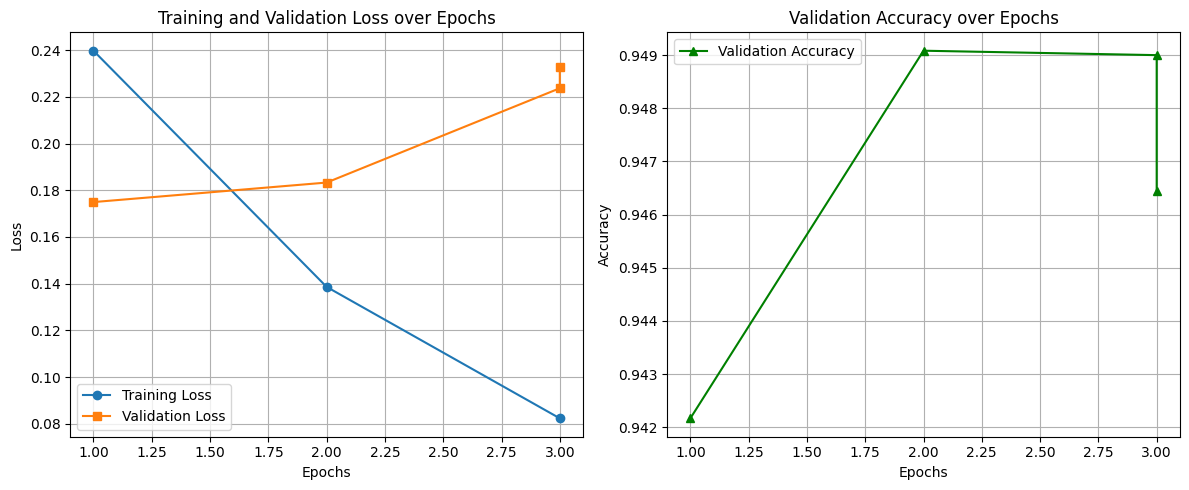

In [ ]:
import matplotlib.pyplot as plt

# Extract metrics from the Trainer's log history
log_history = trainer.state.log_history

train_epochs = []
train_loss = []
val_epochs = []
val_loss = []
val_acc = []

for log in log_history:
    if "loss" in log and "epoch" in log:
        train_epochs.append(log["epoch"])
        train_loss.append(log["loss"])
    elif "eval_loss" in log and "epoch" in log:
        val_epochs.append(log["epoch"])
        val_loss.append(log["eval_loss"])
        val_acc.append(log["eval_accuracy"])

# Plot Training & Validation Loss
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(train_epochs, train_loss, label='Training Loss', marker='o')
plt.plot(val_epochs, val_loss, label='Validation Loss', marker='s')
plt.title('Training and Validation Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot Validation Accuracy
plt.subplot(1, 2, 2)
plt.plot(val_epochs, val_acc, label='Validation Accuracy', color='green', marker='^')
plt.title('Validation Accuracy over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

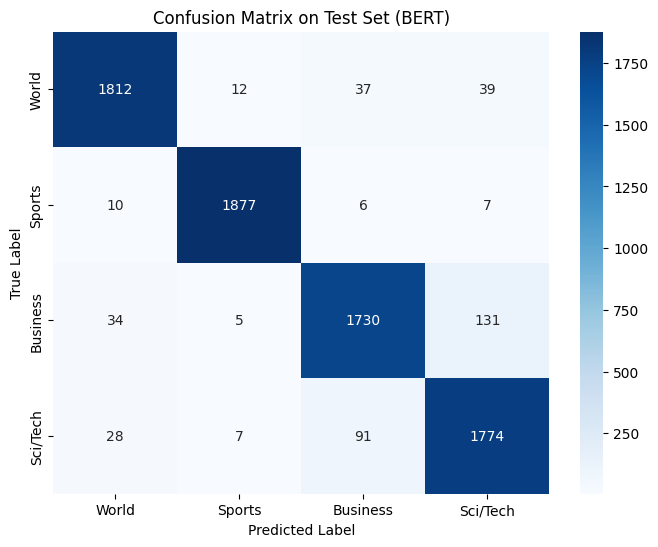

In [ ]:
# Generating a confision matrix
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Get predictions on the test set
predictions_output = trainer.predict(tokenized_test)

y_preds = np.argmax(predictions_output.predictions, axis=1)
y_true = predictions_output.label_ids

# Compute the confusion matrix an plot it
cm = confusion_matrix(y_true, y_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_names, yticklabels=label_names)
plt.title('Confusion Matrix on Test Set (BERT)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

As for the LSTM, the model confuses 'Business' and 'Sci/Tech' the most often when making mistakes, accounting for ~52% of the missclassifications.

In [ ]:
# Extracting missclasificaiton examples
misclassified_indices = np.where(y_preds != y_true)[0]

print(f"Total misclassified examples: {len(misclassified_indices)} out of {len(y_true)}\n")
print("-" * 80)

# Extract and print the first 10 misclassified examples
for i in range(min(10, len(misclassified_indices))):
    idx = misclassified_indices[i]

    text = test_data[int(idx)]["text"]
    true_label_name = label_names[y_true[idx]]
    pred_label_name = label_names[y_preds[idx]]

    print(f"Example {i+1}")
    print(f"True Label:      {true_label_name}")
    print(f"Predicted Label: {pred_label_name}")
    print(f"Text Excerpt:    {text[:200]}...")
    print("-" * 80)

Total misclassified examples: 407 out of 7600

--------------------------------------------------------------------------------
Example 1
True Label:      Sci/Tech
Predicted Label: Business
Text Excerpt:    Some People Not Eligible to Get in on Google IPO Google has billed its IPO as a way for everyday people to get in on the process, denying Wall Street the usual stranglehold it's had on IPOs. Public bi...
--------------------------------------------------------------------------------
Example 2
True Label:      Sci/Tech
Predicted Label: Business
Text Excerpt:    Promoting a Shared Vision As Michael Kaleko kept running into people who were getting older and having more vision problems, he realized he could do something about it....
--------------------------------------------------------------------------------
Example 3
True Label:      Business
Predicted Label: Sci/Tech
Text Excerpt:    Intel to delay product aimed for high-definition TVs SAN FRANCISCO -- In the latest of a series o

Despite achieving higher overall accuracy, the model continues to frequently misclassify instances between the Sci/Tech and Business categories. This reinforces the intuition that there is significant semantic overlap between these two classes within the dataset.

### Task 2: Beyond the Minimum
We analyze different way of training the model to try improve training speed while keeping the accuracy high.

#### Linear Probing

In [ ]:
# Loading a new model
model_frozen = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=4
)

# Freeze the base model
for param in model_frozen.distilbert.parameters():
    param.requires_grad = False

# The new number of parameters
total_params = sum(p.numel() for p in model_frozen.parameters())
trainable_params = sum(p.numel() for p in model_frozen.parameters() if p.requires_grad)

print(f"Total Parameters: {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Total Parameters: 66,956,548
Trainable Parameters: 593,668


In [ ]:
# Training
trainer_frozen = Trainer(
    model=model_frozen,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    compute_metrics=compute_metrics,
)

print("Starting training...")
start_time = time.time()

trainer_frozen.train()

end_time = time.time()
elapsed_seconds = end_time - start_time
formatted_time = str(datetime.timedelta(seconds=int(elapsed_seconds)))
print(f"Total Training Time: {formatted_time} (hh:mm:ss)")

Starting training...


Epoch,Training Loss,Validation Loss,Accuracy
1,0.352315,0.283430,0.897417
2,0.290689,0.269562,0.901833
3,0.281432,0.266066,0.902083


Total Training Time: 0:08:23 (hh:mm:ss)


In [ ]:
# Testing
test_results_frozen = trainer_frozen.evaluate(eval_dataset=tokenized_test)
print(f"Final Test Accuracy: {test_results_frozen['eval_accuracy']:.4f}")

Final Test Accuracy: 0.9009


#### PEFT with LoRA

In [ ]:
from peft import get_peft_model, LoraConfig, TaskType

# Base model
model_base = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=4
)

# Define the LoRA Configuration
lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=8,
    lora_alpha=16,
    lora_dropout=0.1,
    target_modules=["q_lin", "v_lin"]
)

lora_model = get_peft_model(model_base, lora_config)

lora_model.print_trainable_parameters()

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 741,124 || all params: 67,697,672 || trainable%: 1.0948


In [ ]:
# Training
trainer_lora = Trainer(
    model=lora_model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    compute_metrics=compute_metrics,
)

print("Starting training...")
start_time = time.time()

trainer_lora.train()

end_time = time.time()
elapsed_seconds = end_time - start_time
formatted_time = str(datetime.timedelta(seconds=int(elapsed_seconds)))
print(f"Total Training Time: {formatted_time} (hh:mm:ss)")

Starting training...


Epoch,Training Loss,Validation Loss,Accuracy
1,0.285787,0.224892,0.922583
2,0.221544,0.212606,0.928750
3,0.205970,0.204372,0.931750


Total Training Time: 0:15:22 (hh:mm:ss)


In [ ]:
# Testing
test_results_lora = trainer_lora.evaluate(eval_dataset=tokenized_test)
print(f"Final Test Accuracy: {test_results_lora['eval_accuracy']:.4f}")

Final Test Accuracy: 0.9278


#### Comparison

In [ ]:
import pandas as pd

comparison_data = {
    "Model Approach": [
        "DistilBERT (Full Fine-Tuning)",
        "DistilBERT (Frozen Encoder)",
        "DistilBERT (PEFT with LoRA)"
    ],
    "Test Accuracy": [
        f"{test_results['eval_accuracy'] * 100:.2f}%",
        f"{test_results_frozen['eval_accuracy'] * 100:.2f}%",
        f"{test_results_lora['eval_accuracy'] * 100:.2f}%"
    ],
    "Validation Accuracy (Best)": [
        "94.9%",
        "90.2%",
        "93.2%"
    ],
    "Approx. Trainable Parameters": [
        "~66,9 Million",
        "593,668",
        "741,124"
    ],
    "Estimated Training Time (mm:ss)": [
        "23:42",
        "8:23",
        "15:22"
    ]
}

df_comparison = pd.DataFrame(comparison_data)

display(df_comparison)

,Model Approach,Test Accuracy,Validation Accuracy (Best),Approx. Trainable Parameters,Estimated Training Time (mm:ss)
0,DistilBERT (Full Fine-Tuning),94.64%,94.9%,"~66,9 Million",23:42
1,DistilBERT (Frozen Encoder),90.09%,90.2%,"593,668",8:23
2,DistilBERT (PEFT with LoRA),92.78%,93.2%,"741,124",15:22


Full Fine-Tuning (Highest Accuracy): Yields the best test accuracy (94.4%) by updating all ~66.9 million parameters to adapt deeply to the specific task, but requires the most computational time (23:19).

Frozen Encoder (Fastest): Acts as a highly efficient feature extractor. By only training the final classification head (~593k parameters), it trains in roughly a third of the time (7:57) while still maintaining a respectable 90.17% accuracy.

PEFT with LoRA (Best Balance): Offers a powerful middle ground. While it trains a similar number of parameters to the Frozen Encoder (~741k), it injects them directly into the deeper attention mechanisms. This allows it to achieve near full-tuning accuracy (92.8%) in significantly less time (15:15).

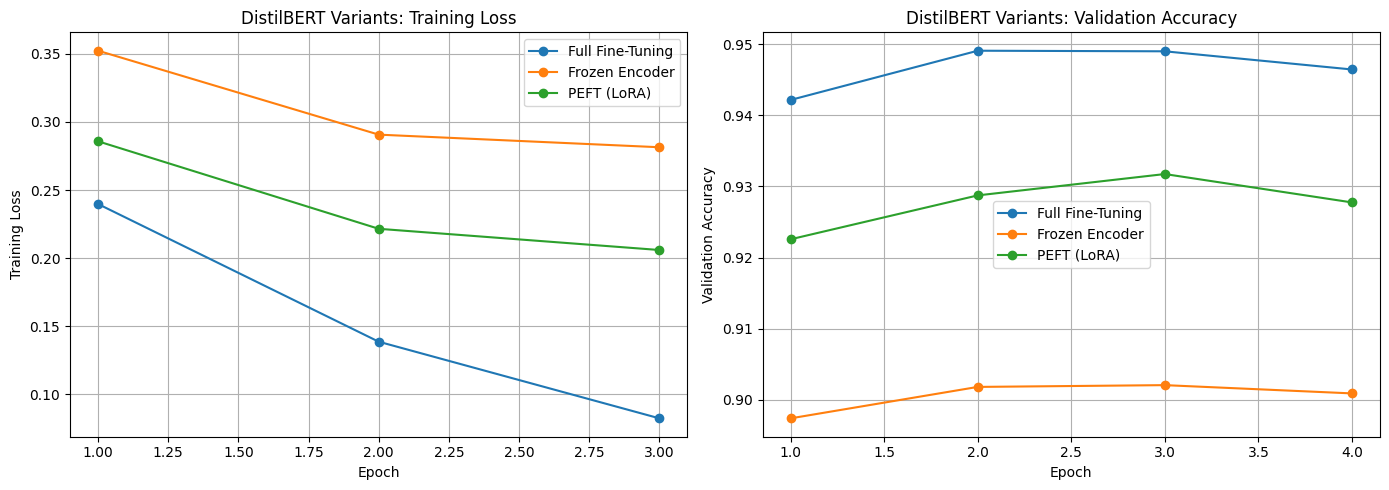

In [ ]:
def extract_bert_history(trainer_obj):
    train_loss = []
    val_acc = []
    for log in trainer_obj.state.log_history:
        if "loss" in log and "epoch" in log:
            train_loss.append(log["loss"])
        elif "eval_accuracy" in log and "epoch" in log:
            val_acc.append(log["eval_accuracy"])
    return train_loss, val_acc

bert_variants = {
    "Full Fine-Tuning": trainer,
    "Frozen Encoder": trainer_frozen,
    "PEFT (LoRA)": trainer_lora
}

plt.figure(figsize=(14, 5))

# Training Loss Comparison
plt.subplot(1, 2, 1)
for name, t in bert_variants.items():
    train_loss, _ = extract_bert_history(t)
    epochs = range(1, len(train_loss) + 1)
    plt.plot(epochs, train_loss, marker="o", label=name)
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("DistilBERT Variants: Training Loss")
plt.legend()
plt.grid(True)

# Validation Accuracy Comparison
plt.subplot(1, 2, 2)
for name, t in bert_variants.items():
    _, val_acc = extract_bert_history(t)
    epochs = range(1, len(val_acc) + 1)
    plt.plot(epochs, val_acc, marker="o", label=name)
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("DistilBERT Variants: Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()